In [17]:
library(lme4)
library(lmerTest)
library(ggplot2)
library(mgcv)
library(plotly)
library(parallel)
library(MuMIn)
library(ggeffects)
library(car)
library(tidyr)
library(dplyr)
library(glmmTMB)
rescale_01 <- function(x) {
  (x - min(x, na.rm = TRUE)) / (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))
}

residual_test <- function(model){
hist(residuals(model), main = "Histogram of Residuals", xlab = "Residuals")
qqnorm(residuals(model))
qqline(residuals(model), col = "red")
# shapiro.test(residuals(model))
ks.test(residuals(model), "pnorm", mean = mean(residuals(model)), sd = sd(residuals(model)))}

df <- read.csv("../../../data_processing/combine_data/results_aeema.csv")

In [18]:
df <- df[!df$is_limited, ]
df <- df[!df$cross_syllable_boundary, ]
df <- df[df$data_space=="latent", ]

df[df$modality=="art",]$dist <- scale(df[df$modality=="art",]$dist)
df[df$modality=="ac",]$dist <- scale(df[df$modality=="ac",]$dist)

df$phone1_H_art_given_ac <- scale(df$phone1_H_art_given_ac)
df$phone2_H_art_given_ac <- scale(df$phone2_H_art_given_ac)
df$phone2_freq <- scale(log(df$phone2_freq))
df$bigram_surprisal <- as.numeric(scale(df$bigram_surprisal))

df$subject <- as.factor(df$subject)
df$word <- as.factor(df$word)
df$bigram <- as.factor(paste(df$phone1, df$phone2, sep = "_"))

df$token_id <- as.factor(paste(df$word_id, df$phone1_start, sep = "_"))

df$modality <- as.factor(df$modality)
contrasts(df$modality) <- c(-0.5, 0.5)
print(contrasts(df$modality))
print("n rows:")
print(nrow(df))

df$phone1_duration <- df$phone1_end - df$phone1_start
df$phone1_duration <- scale(df$phone1_duration)
df$phone2_duration <- df$phone2_end - df$phone2_start
df$phone2_duration <- scale(df$phone2_duration)

    [,1]
ac  -0.5
art  0.5
[1] "n rows:"
[1] 36544


In [19]:
# model <- lmer(
#   dist ~ bigram_surprisal *
#          modality *

#          phone2_H_art_given_ac *
#          phone1_H_art_given_ac *

#          phone2_duration *

#          phone2_freq +
    
#     (1 | token_id) +
#     (bigram_surprisal + modality || word) + 
#     (bigram_surprisal + modality || bigram) + 
#     (bigram_surprisal + modality || subject),
#   data = df,
#   control = lmerControl(
#     optimizer = "bobyqa",
#     optCtrl = list(maxfun = 2e5)
#   )
# )
# summary(model)

In [20]:
model <- lmer(
  dist ~ bigram_surprisal *
         modality *

         phone2_H_art_given_ac *
         phone1_H_art_given_ac *

         phone2_duration *
         phone1_duration *

         phone2_freq +

    (1 | word) + 
    (bigram_surprisal | bigram) + 
    (bigram_surprisal | subject),
  data = df,
  control = lmerControl(
    optimizer = "bobyqa",
    optCtrl = list(maxfun = 2e5)
  )
)
summary(model)


Correlation matrix not shown by default, as p = 128 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: dist ~ bigram_surprisal * modality * phone2_H_art_given_ac *  
    phone1_H_art_given_ac * phone2_duration * phone1_duration *  
    phone2_freq + (1 | word) + (bigram_surprisal | bigram) +  
    (bigram_surprisal | subject)
   Data: df
Control: lmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 2e+05))

REML criterion at convergence: 92685.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.0233 -0.5975 -0.1960  0.3443  7.9392 

Random effects:
 Groups   Name             Variance Std.Dev. Corr 
 word     (Intercept)      0.033909 0.18414       
 bigram   (Intercept)      0.049695 0.22292       
          bigram_surprisal 0.005368 0.07327  0.28 
 subject  (Intercept)      0.008041 0.08967       
          bigram_surprisal 0.001469 0.03832  -0.28
 Residual                  0.851360 0.92269       
Number of obs: 33796, groups:  word, 1485; bigram, 311; subject, 4

Fixed eff

In [21]:
library(emmeans)
tr <- emtrends(model, ~ modality, var = "bigram_surprisal")
summary(tr, infer = c(TRUE, TRUE))

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 33796' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 33796)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 33796' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 33796)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,modality,bigram_surprisal.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ac,0.06881749,0.02240626,Inf,0.02490203,0.1127330,3.071351,0.002130925
2,art,0.05837327,0.02241091,Inf,0.01444869,0.1022979,2.604681,0.009195994


In [22]:
get_term_base <- function(model, term_name) {
  coef_table <- summary(model)$coefficients
  estimate <- coef_table[term_name, "Estimate"]
  p_value <- if(length(grep("Pr\\(>|p-value", colnames(coef_table), value = TRUE)) > 0) coef_table[term_name, grep("Pr\\(>|p-value", colnames(coef_table), value = TRUE)] else NA
  return(list(sign = ifelse(estimate > 0, "+", "-"), p_value = p_value,significant = (!is.na(p_value) && p_value < 0.05)))
}
get_term_base(model, "bigram_surprisal")
get_term_base(model, "bigram_surprisal:modality1:phone2_H_art_given_ac")

$sign
[1] "+"

$p_value
[1] 0.03992271

$significant
[1] TRUE

$sign
[1] "-"

$p_value
[1] 0.8800976

$significant
[1] FALSE

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


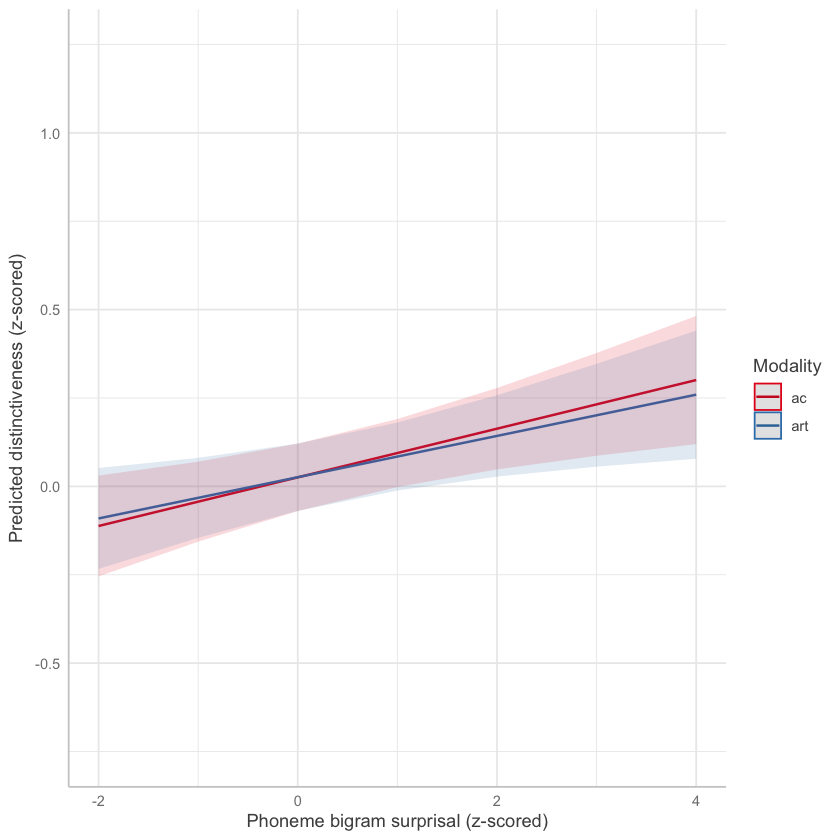

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


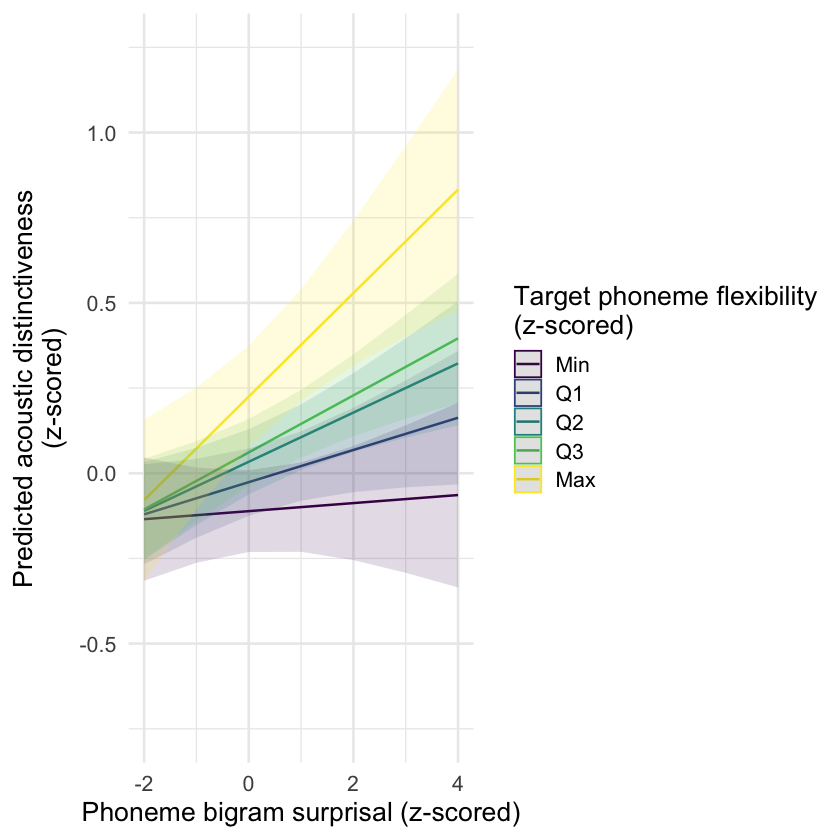

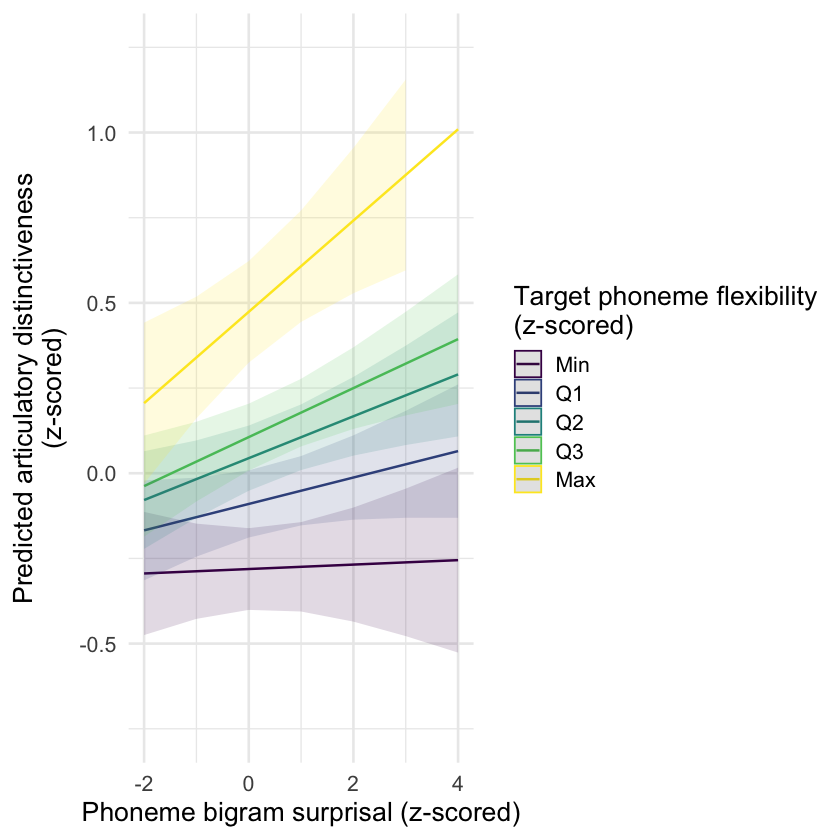

In [23]:
qs <- quantile(df$phone2_H_art_given_ac,
               probs = c(0, 0.25, 0.5, 0.75, 1),
               na.rm = TRUE)
vals <- as.numeric(qs)   # convert named quantile vector to numeric


preds <- ggpredict(model, terms = c("bigram_surprisal", "modality [ac, art]"))

preds$group <- factor(preds$group,
                      labels = c("ac", "art"))

p <- plot(preds) + labs(color = "Modality") + xlab("Phoneme bigram surprisal (z-scored)") + ylab("Predicted distinctiveness (z-scored)") + ggtitle(NULL) + ylim(-0.75, 1.25)
p
# write.csv(preds, "preds_surprisal.csv", row.names = FALSE)

preds <- ggpredict(model, terms = c("bigram_surprisal", sprintf("phone2_H_art_given_ac [%s]",
            paste(round(vals, 4), collapse = ", ")), "modality [ac]"))

preds$group <- factor(preds$group,
                      labels = c("Min", "Q1", "Q2", "Q3", "Max"))

p <- plot(preds) +
  labs(color = "Target phoneme flexibility\n(z-scored)") +
  xlab("Phoneme bigram surprisal (z-scored)") +
  ylab("Predicted acoustic distinctiveness\n(z-scored)") +
  ggtitle(NULL) +
  ylim(-0.75, 1.25) +
  scale_color_viridis_d(option = "viridis") +
  scale_fill_viridis_d(option = "viridis") +
  theme_minimal(base_size = 16)

# ggsave("acousticplot.png", plot = p, width = 8, height = 4.3, dpi = 300)
p
# write.csv(preds, "../preds_acoustics.csv", row.names = FALSE)


preds <- ggpredict(model, terms = c("bigram_surprisal", sprintf("phone2_H_art_given_ac [%s]",
            paste(round(vals, 4), collapse = ", ")), "modality [art]"))

preds$group <- factor(preds$group,
                      labels = c("Min", "Q1", "Q2", "Q3", "Max"))

p <- plot(preds) +
  labs(color = "Target phoneme flexibility\n(z-scored)") +
  xlab("Phoneme bigram surprisal (z-scored)") +
  ylab("Predicted articulatory distinctiveness\n(z-scored)") +
  ggtitle(NULL) +
  ylim(-0.75, 1.25) +
  scale_color_viridis_d(option = "viridis") +
  scale_fill_viridis_d(option = "viridis") +
  theme_minimal(base_size = 16)

# ggsave("articulatoryplot.png", plot = p, width = 8, height = 4.3, dpi = 300)
p
# write.csv(preds, "../preds_articulatory.csv", row.names = FALSE)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 33796' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 33796)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 33796' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 33796)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions

ERROR while rich displaying an object: Error in `geom_ribbon()`:
! Problem while computing aesthetics.
ℹ Error occurred in the 3rd layer.
Caused by error:
! object 'lower.CL' not found

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(w

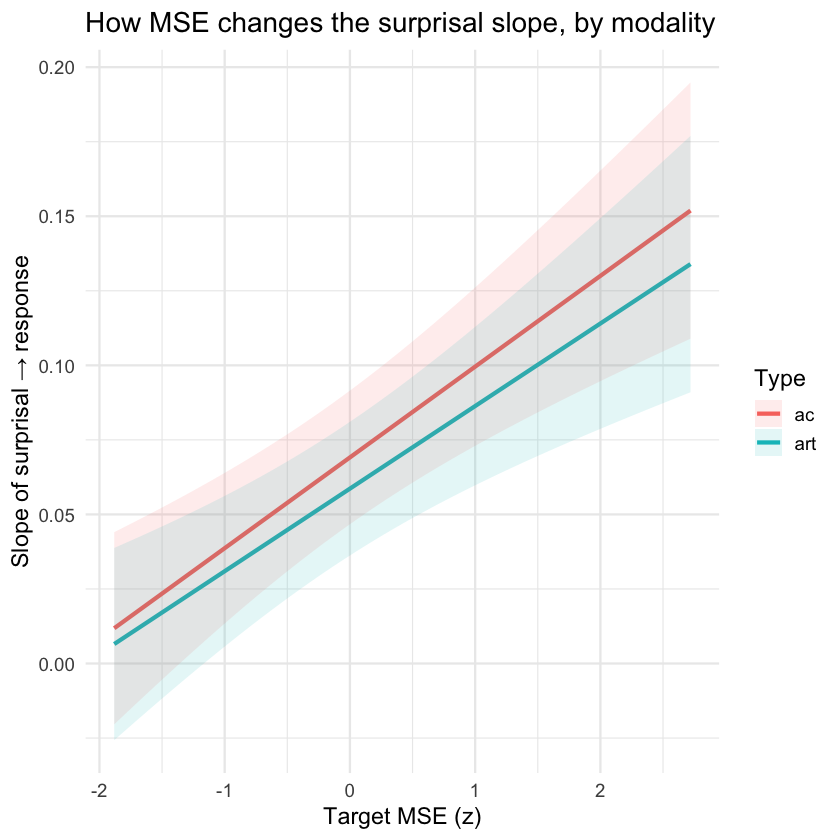

In [24]:
library(emmeans)
library(dplyr)
library(ggplot2)

# 1) Slopes (trends) of surprisal across a smooth MSE grid
mse_grid <- seq(min(df$phone2_H_art_given_ac, na.rm = TRUE),
                max(df$phone2_H_art_given_ac, na.rm = TRUE),
                length.out = 75)

em_curve <- emtrends(
  model,
  specs = ~ modality * phone2_H_art_given_ac,
  var   = "bigram_surprisal",
  at    = list(phone2_H_art_given_ac = mse_grid)
)

curve_df <- as.data.frame(em_curve) %>%
  # emtrends names the slope column like "surprisal.trend"
  rename(slope = !!grep("trend$", names(.), value = TRUE),
         mse   = phone2_H_art_given_ac)

ggplot(curve_df, aes(x = mse, y = slope, color = modality)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = slope - SE, ymax = slope + SE, fill = modality),
              alpha = 0.12, color = NA) +
  labs(x = "Target MSE (z)",
       y = "Slope of surprisal → response",
       color = "Type", fill = "Type",
       title = "How MSE changes the surprisal slope, by modality") +
  theme_minimal(base_size = 14)

diff_curve <- contrast(
  em_curve,
  method = "pairwise",                    # (acoustic - articulatory)
  by     = "phone2_H_art_given_ac"
)

diff_df <- as.data.frame(diff_curve, infer = c(TRUE, TRUE)) %>%
  dplyr::rename(delta_slope = estimate,
                mse         = phone2_H_art_given_ac)

ggplot(diff_df, aes(x = mse, y = delta_slope)) +
  geom_hline(yintercept = 0, linetype = 2) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower.CL, ymax = upper.CL), alpha = 0.15) +
  labs(x = "Phone2 flexibility (z)",
       y = "Δ slope (acoustic − articulatory)",
       title = "Difference in surprisal slope between modalities across flexibility") +
  theme_minimal(base_size = 14)
# write.csv(diff_df, "../diff_df.csv", row.names = FALSE)